# D Mart Data Analysis Project

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries

In [3]:
df = pd.read_csv("Dmart_data.csv", delimiter = ',', encoding = 'utf-8')

In [4]:
df.head(5)

,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
0,2023-12-31 15:41:00,06:04:28,Member,Grocery,10.69,4,42.76,Jai Bhatia,December,2023,Sunday,6,10.69
1,2024-01-07 22:19:00,01:05:18,Premium,Home & Kitchen,381.03,3,1143.09,Ishaan Patel,January,2024,Sunday,1,381.03
2,2024-01-10 02:09:00,17:31:43,Regular,Grocery,153.84,5,769.20,Tanvi Iyer,January,2024,Wednesday,17,153.84
3,2023-06-01 10:46:00,01:50:16,Regular,Electronics,341.41,4,1365.64,Zara Xavier,June,2023,Thursday,1,341.41
4,2024-05-23 22:07:00,10:37:06,Regular,Home & Kitchen,390.16,5,1950.80,Krishna Zutshi,May,2024,Thursday,10,390.16


In [5]:
df.tail(5)

,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
6552,2023-08-08 08:13:00,23:21:26,Premium,Beauty & Personal Care,344.70,3,1034.10,Lakshmi Zutshi,August,2023,Tuesday,23,344.70
6553,2023-12-12 00:15:00,09:40:43,Member,Electronics,236.84,4,947.36,Diya Desai,December,2023,Tuesday,9,236.84
6554,2024-11-26 14:55:00,18:04:11,Premium,Home & Kitchen,455.58,4,1822.32,Ishaan Chauhan,November,2024,Tuesday,18,455.58
6555,2024-01-11 17:26:00,22:14:00,Regular,Beauty & Personal Care,437.02,1,437.02,Ishaan Kumar,January,2024,Thursday,22,437.02
6556,2024-11-08 16:31:00,21:51:02,Premium,Clothing,282.43,3,847.29,Jai Iyer,November,2024,Friday,21,282.40


# Data Information

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6557 entries, 0 to 6556
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   DATE              6557 non-null   object 
 1   TIME              6557 non-null   object 
 2   CUSTOMERTYPE      6557 non-null   object 
 3   PRODUCTCATEGORY   6557 non-null   object 
 4   UNITPRICE         6557 non-null   float64
 5   QUANTITY          6557 non-null   int64  
 6   TOTAL             6557 non-null   float64
 7   FULLNAME          6557 non-null   object 
 8   MONTH             6557 non-null   object 
 9   YEAR              6557 non-null   int64  
 10  DAY_OF_WEEK       6557 non-null   object 
 11  HOUR              6557 non-null   int64  
 12  REVENUE_PER_UNIT  6557 non-null   float64
dtypes: float64(3), int64(3), object(7)
memory usage: 666.1+ KB


In [7]:
df.describe()

,UNITPRICE,QUANTITY,TOTAL,YEAR,HOUR,REVENUE_PER_UNIT
count,6557.000000,6557.000000,6557.000000,6557.000000,6557.000000,6557.000000
mean,253.144241,2.992070,759.963470,2023.504041,11.591734,253.144237
std,142.582365,1.435176,602.887092,0.523566,6.874830,142.582364
min,10.060000,1.000000,10.060000,2023.000000,0.000000,10.060000
25%,128.770000,2.000000,279.240000,2023.000000,6.000000,128.770000
50%,255.030000,3.000000,577.160000,2023.000000,12.000000,255.030000
75%,375.920000,4.000000,1124.250000,2024.000000,18.000000,375.920000
max,499.900000,5.000000,2499.500000,2025.000000,23.000000,499.900000


In [8]:
df.isnull().sum()

DATE                0
TIME                0
CUSTOMERTYPE        0
PRODUCTCATEGORY     0
UNITPRICE           0
QUANTITY            0
TOTAL               0
FULLNAME            0
MONTH               0
YEAR                0
DAY_OF_WEEK         0
HOUR                0
REVENUE_PER_UNIT    0
dtype: int64

# size of Data in terms of (rows and Columns)

In [9]:
print("Data Size : ",df.shape)

Data Size :  (6557, 13)


# list of all columns present in data

In [10]:
df.columns

Index(['DATE', 'TIME', 'CUSTOMERTYPE', 'PRODUCTCATEGORY', 'UNITPRICE',
       'QUANTITY', 'TOTAL', 'FULLNAME', 'MONTH', 'YEAR', 'DAY_OF_WEEK', 'HOUR',
       'REVENUE_PER_UNIT'],
      dtype='object')

In [11]:
df.dtypes

DATE                 object
TIME                 object
CUSTOMERTYPE         object
PRODUCTCATEGORY      object
UNITPRICE           float64
QUANTITY              int64
TOTAL               float64
FULLNAME             object
MONTH                object
YEAR                  int64
DAY_OF_WEEK          object
HOUR                  int64
REVENUE_PER_UNIT    float64
dtype: object

In [12]:
df['CUSTOMERTYPE'].value_counts()

CUSTOMERTYPE
Regular    2238
Premium    2179
Member     2140
Name: count, dtype: int64

In [13]:
df['PRODUCTCATEGORY'].value_counts()

PRODUCTCATEGORY
Clothing                  1343
Electronics               1338
Beauty & Personal Care    1337
Grocery                   1281
Home & Kitchen            1258
Name: count, dtype: int64

# Data Cleaning

In [14]:
df1 = df.drop_duplicates()
df1 = df.fillna(0)
df1['DATE'] = pd.to_datetime(df['DATE'],dayfirst = True) # Fix the datetype
df1['TIME'] = pd.to_datetime(df['TIME'], format = '%H:%M:%S').dt.time
df1.columns = df.columns.str.strip().str.upper() 
df1.head(20)

/tmp/ipykernel_833/3195392617.py:3: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df1['DATE'] = pd.to_datetime(df['DATE'],dayfirst = True) # Fix the datetype


,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
0,2023-12-31 15:41:00,06:04:28,Member,Grocery,10.69,4,42.76,Jai Bhatia,December,2023,Sunday,6,10.69
1,2024-01-07 22:19:00,01:05:18,Premium,Home & Kitchen,381.03,3,1143.09,Ishaan Patel,January,2024,Sunday,1,381.03
2,2024-01-10 02:09:00,17:31:43,Regular,Grocery,153.84,5,769.20,Tanvi Iyer,January,2024,Wednesday,17,153.84
3,2023-06-01 10:46:00,01:50:16,Regular,Electronics,341.41,4,1365.64,Zara Xavier,June,2023,Thursday,1,341.41
4,2024-05-23 22:07:00,10:37:06,Regular,Home & Kitchen,390.16,5,1950.80,Krishna Zutshi,May,2024,Thursday,10,390.16
5,2024-02-16 19:41:00,22:41:47,Member,Grocery,170.21,4,680.84,Zara Singh,February,2024,Friday,22,170.21
6,2023-11-30 03:36:00,09:36:45,Member,Clothing,81.74,2,163.48,Eeshaan Xavier,November,2023,Thursday,9,81.74
7,2024-06-05 05:21:00,20:02:39,Premium,Clothing,181.26,3,543.78,Eeshaan Kumar,June,2024,Wednesday,20,181.26
8,2024-06-07 21:40:00,21:07:44,Premium,Electronics,471.89,2,943.78,Mahesh Mehta,June,2024,Friday,21,471.89
9,2023-12-29 04:35:00,17:53:54,Member,Grocery,59.70,2,119.40,Ishaan Verma,December,2023,Friday,17,59.70


In [15]:
df1['MONTH'] = df1['DATE'].dt.month_name()
df1['YEAR'] = df1['DATE'].dt.year
df1['DAY_OF_WEEK'] = df1['DATE'].dt.day_name()
df1['HOUR'] = pd.to_datetime(df1['TIME'], format='%H:%M:%S').dt.hour
df1['REVENUE_PER_UNIT'] = df1['TOTAL'] / df['QUANTITY']
df1.head()

,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
0,2023-12-31 15:41:00,06:04:28,Member,Grocery,10.69,4,42.76,Jai Bhatia,December,2023,Sunday,6,10.69
1,2024-01-07 22:19:00,01:05:18,Premium,Home & Kitchen,381.03,3,1143.09,Ishaan Patel,January,2024,Sunday,1,381.03
2,2024-01-10 02:09:00,17:31:43,Regular,Grocery,153.84,5,769.20,Tanvi Iyer,January,2024,Wednesday,17,153.84
3,2023-06-01 10:46:00,01:50:16,Regular,Electronics,341.41,4,1365.64,Zara Xavier,June,2023,Thursday,1,341.41
4,2024-05-23 22:07:00,10:37:06,Regular,Home & Kitchen,390.16,5,1950.80,Krishna Zutshi,May,2024,Thursday,10,390.16


In [16]:
# Same as above but cleaner syntax
df1.query("CUSTOMERTYPE == 'Premium'")
df1.query("TOTAL > 1000")
df1.query("CUSTOMERTYPE == 'Premium' and TOTAL > 1000")
df1.query("PRODUCTCATEGORY == 'Grocery' or PRODUCTCATEGORY == 'Electronics'")

# Using 'in' for multiple values
#df.query("PRODUCTCATEGORY in ['Grocery', 'Electronics']")

,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
0,2023-12-31 15:41:00,06:04:28,Member,Grocery,10.69,4,42.76,Jai Bhatia,December,2023,Sunday,6,10.69
2,2024-01-10 02:09:00,17:31:43,Regular,Grocery,153.84,5,769.20,Tanvi Iyer,January,2024,Wednesday,17,153.84
3,2023-06-01 10:46:00,01:50:16,Regular,Electronics,341.41,4,1365.64,Zara Xavier,June,2023,Thursday,1,341.41
5,2024-02-16 19:41:00,22:41:47,Member,Grocery,170.21,4,680.84,Zara Singh,February,2024,Friday,22,170.21
8,2024-06-07 21:40:00,21:07:44,Premium,Electronics,471.89,2,943.78,Mahesh Mehta,June,2024,Friday,21,471.89
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6544,2024-08-11 03:32:00,11:42:18,Premium,Grocery,375.89,1,375.89,Diya Yadav,August,2024,Sunday,11,375.89
6545,2023-01-22 15:02:00,01:14:37,Regular,Electronics,147.83,4,591.32,Ishaan Iyer,January,2023,Sunday,1,147.83
6550,2023-10-25 23:05:00,02:36:35,Member,Grocery,326.01,3,978.03,Mahesh Mehta,October,2023,Wednesday,2,326.01
6551,2023-11-04 02:18:00,03:28:20,Member,Electronics,381.31,4,1525.24,Eeshaan Agarwal,November,2023,Saturday,3,381.31


In [17]:
df1.query("YEAR =='2023'")
df1.query("MONTH == 'August' ") 
df1.query("CUSTOMERTYPE == 'Regular' ")

,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
2,2024-01-10 02:09:00,17:31:43,Regular,Grocery,153.84,5,769.20,Tanvi Iyer,January,2024,Wednesday,17,153.84
3,2023-06-01 10:46:00,01:50:16,Regular,Electronics,341.41,4,1365.64,Zara Xavier,June,2023,Thursday,1,341.41
4,2024-05-23 22:07:00,10:37:06,Regular,Home & Kitchen,390.16,5,1950.80,Krishna Zutshi,May,2024,Thursday,10,390.16
10,2024-12-13 15:25:00,21:08:19,Regular,Electronics,198.48,4,793.92,Krishna Agarwal,December,2024,Friday,21,198.48
15,2023-12-30 06:34:00,20:28:06,Regular,Electronics,104.18,3,312.54,Bhavesh Verma,December,2023,Saturday,20,104.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6532,2024-05-03 02:16:00,14:06:10,Regular,Grocery,223.26,3,669.78,Rohan Desai,May,2024,Friday,14,223.26
6541,2023-07-05 15:42:00,10:50:10,Regular,Home & Kitchen,166.51,5,832.55,Gaurav Singh,July,2023,Wednesday,10,166.51
6545,2023-01-22 15:02:00,01:14:37,Regular,Electronics,147.83,4,591.32,Ishaan Iyer,January,2023,Sunday,1,147.83
6548,2024-09-02 03:23:00,22:43:51,Regular,Clothing,48.42,2,96.84,Shreya Iyer,September,2024,Monday,22,48.42


In [18]:
df1[(df1['TOTAL'] >= 500) & (df1['TOTAL'] <= 1000)]  # compare prices 

,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
2,2024-01-10 02:09:00,17:31:43,Regular,Grocery,153.84,5,769.20,Tanvi Iyer,January,2024,Wednesday,17,153.84
5,2024-02-16 19:41:00,22:41:47,Member,Grocery,170.21,4,680.84,Zara Singh,February,2024,Friday,22,170.21
7,2024-06-05 05:21:00,20:02:39,Premium,Clothing,181.26,3,543.78,Eeshaan Kumar,June,2024,Wednesday,20,181.26
8,2024-06-07 21:40:00,21:07:44,Premium,Electronics,471.89,2,943.78,Mahesh Mehta,June,2024,Friday,21,471.89
10,2024-12-13 15:25:00,21:08:19,Regular,Electronics,198.48,4,793.92,Krishna Agarwal,December,2024,Friday,21,198.48
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6546,2023-09-27 14:42:00,21:34:06,Premium,Beauty & Personal Care,171.67,4,686.68,Yash Mehta,September,2023,Wednesday,21,171.67
6547,2024-01-22 08:55:00,00:28:15,Member,Clothing,148.50,4,594.00,Nandini Singh,January,2024,Monday,0,148.50
6550,2023-10-25 23:05:00,02:36:35,Member,Grocery,326.01,3,978.03,Mahesh Mehta,October,2023,Wednesday,2,326.01
6553,2023-12-12 00:15:00,09:40:43,Member,Electronics,236.84,4,947.36,Diya Desai,December,2023,Tuesday,9,236.84


In [19]:

df1[df1['FULLNAME'] == 'Jai Bhatia']   # purchase made by specific customer 

,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
0,2023-12-31 15:41:00,06:04:28,Member,Grocery,10.69,4,42.76,Jai Bhatia,December,2023,Sunday,6,10.69
323,2025-01-01 21:57:00,15:18:45,Regular,Home & Kitchen,171.23,4,684.92,Jai Bhatia,January,2025,Wednesday,15,171.23
397,2024-04-23 16:43:00,02:21:36,Premium,Clothing,498.72,5,2493.60,Jai Bhatia,April,2024,Tuesday,2,498.72
1357,2024-08-24 11:08:00,12:55:41,Premium,Beauty & Personal Care,173.04,2,346.08,Jai Bhatia,August,2024,Saturday,12,173.04
1542,2023-01-22 15:45:00,02:11:56,Member,Home & Kitchen,439.13,3,1317.39,Jai Bhatia,January,2023,Sunday,2,439.13
1650,2023-02-22 22:21:00,12:21:17,Premium,Clothing,474.93,2,949.86,Jai Bhatia,February,2023,Wednesday,12,474.93
1851,2023-03-19 02:12:00,03:12:42,Regular,Electronics,231.64,2,463.28,Jai Bhatia,March,2023,Sunday,3,231.64
1884,2023-01-27 21:16:00,19:36:55,Regular,Electronics,437.49,2,874.98,Jai Bhatia,January,2023,Friday,19,437.49
2460,2024-01-22 07:08:00,21:25:43,Premium,Grocery,54.61,3,163.83,Jai Bhatia,January,2024,Monday,21,54.61
3206,2024-10-18 01:06:00,15:56:36,Member,Electronics,293.85,4,1175.40,Jai Bhatia,October,2024,Friday,15,293.85


In [20]:
# NOT a Regular customer (~ means NOT)
df1[~(df1['CUSTOMERTYPE'] == 'Regular')]

,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
0,2023-12-31 15:41:00,06:04:28,Member,Grocery,10.69,4,42.76,Jai Bhatia,December,2023,Sunday,6,10.69
1,2024-01-07 22:19:00,01:05:18,Premium,Home & Kitchen,381.03,3,1143.09,Ishaan Patel,January,2024,Sunday,1,381.03
5,2024-02-16 19:41:00,22:41:47,Member,Grocery,170.21,4,680.84,Zara Singh,February,2024,Friday,22,170.21
6,2023-11-30 03:36:00,09:36:45,Member,Clothing,81.74,2,163.48,Eeshaan Xavier,November,2023,Thursday,9,81.74
7,2024-06-05 05:21:00,20:02:39,Premium,Clothing,181.26,3,543.78,Eeshaan Kumar,June,2024,Wednesday,20,181.26
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6551,2023-11-04 02:18:00,03:28:20,Member,Electronics,381.31,4,1525.24,Eeshaan Agarwal,November,2023,Saturday,3,381.31
6552,2023-08-08 08:13:00,23:21:26,Premium,Beauty & Personal Care,344.70,3,1034.10,Lakshmi Zutshi,August,2023,Tuesday,23,344.70
6553,2023-12-12 00:15:00,09:40:43,Member,Electronics,236.84,4,947.36,Diya Desai,December,2023,Tuesday,9,236.84
6554,2024-11-26 14:55:00,18:04:11,Premium,Home & Kitchen,455.58,4,1822.32,Ishaan Chauhan,November,2024,Tuesday,18,455.58


In [21]:

#  Top 5 highest transactions
df1.nlargest(5, 'TOTAL')

#  Bottom 5 lowest transactions
df1.nsmallest(5, 'TOTAL')

,DATE,TIME,CUSTOMERTYPE,PRODUCTCATEGORY,UNITPRICE,QUANTITY,TOTAL,FULLNAME,MONTH,YEAR,DAY_OF_WEEK,HOUR,REVENUE_PER_UNIT
1569,2024-04-12 11:39:00,13:31:49,Member,Beauty & Personal Care,10.06,1,10.06,Lakshmi Agarwal,April,2024,Friday,13,10.06
6425,2023-08-22 15:19:00,12:54:12,Member,Grocery,10.22,1,10.22,Vaibhav Kumar,August,2023,Tuesday,12,10.22
5907,2024-04-08 07:16:00,12:23:30,Regular,Grocery,10.82,1,10.82,Jai Desai,April,2024,Monday,12,10.82
2908,2023-01-05 07:54:00,09:07:03,Regular,Home & Kitchen,10.95,1,10.95,Tanvi Lal,January,2023,Thursday,9,10.95
718,2024-11-05 21:05:00,23:18:25,Premium,Clothing,11.31,1,11.31,Yash Patel,November,2024,Tuesday,23,11.31


# Total Sales by Product Category

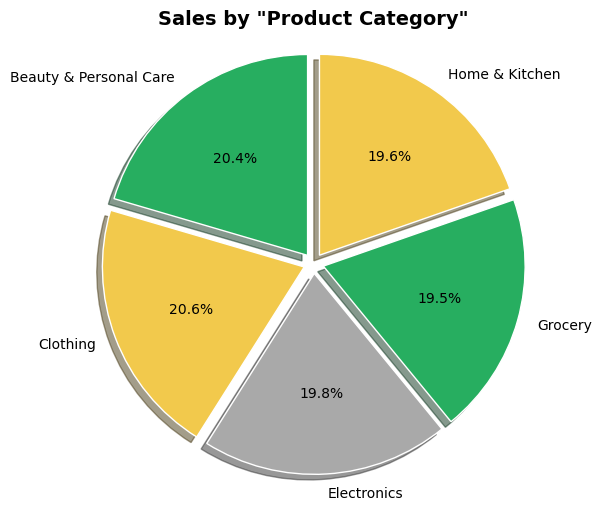

In [22]:
sales_by_Product =df1.groupby('PRODUCTCATEGORY')['TOTAL'].sum()
colors = ['#27AE60', '#F2C94C', '#A9A9A9']  # green, yellow, grey
explode = [0.05] * len(sales_by_Product)

plt.figure(figsize=(6,6))
plt.pie(
    sales_by_Product,
    labels = sales_by_Product.index,
    autopct='%.1f%%',
    startangle=90,
    colors=colors,
    wedgeprops={'edgecolor': 'white'},  # clean borders
    explode=explode,
    shadow=True
)
plt.title('Sales by "Product Category"', fontsize=14, fontweight='bold')
plt.axis('equal')


plt.show()

# Total Sales by Customer Type

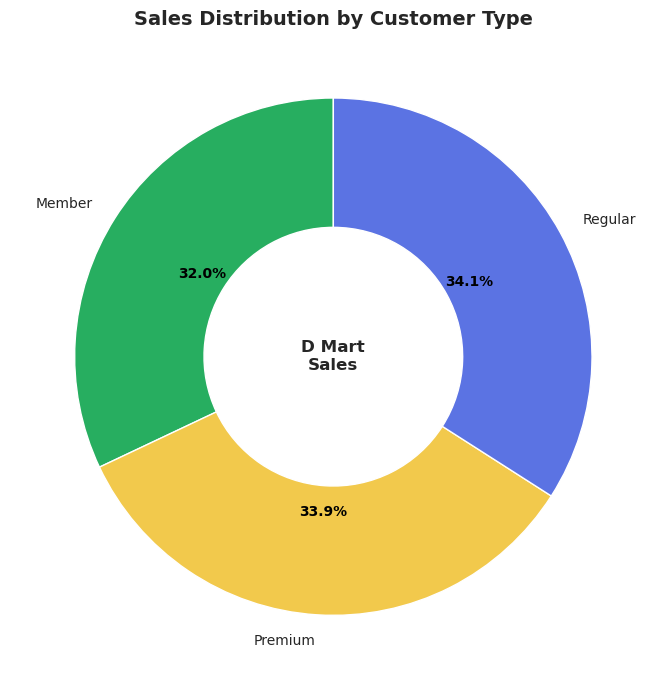

In [23]:
sales_by_size = df.groupby('CUSTOMERTYPE')['TOTAL'].sum()

plt.figure(figsize=(7,7))
plt.style.use('seaborn-v0_8-whitegrid')

Dmart_colors = ['#27AE60', '#F2C94C', '#5B73E3']

wedges, texts, autotexts = plt.pie(
    sales_by_size,
    labels=sales_by_size.index,
    autopct='%1.1f%%',
    startangle=90,
    colors= Dmart_colors,
    wedgeprops={'width':0.5, 'edgecolor':'white'},
    #shadow=True
)

# Center text (donut style)
plt.text(0, 0, 'D Mart\nSales', ha='center', va='center',
         fontsize=12, fontweight='bold')

plt.title('Sales Distribution by Customer Type', fontsize=14, fontweight='bold')

# Beautify percentage text
for autotext in autotexts:
    autotext.set_color('black')
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

plt.tight_layout()
plt.show()

In [24]:
print(df1['YEAR'].unique())

[2023 2024 2025]


# Yearwise Sales

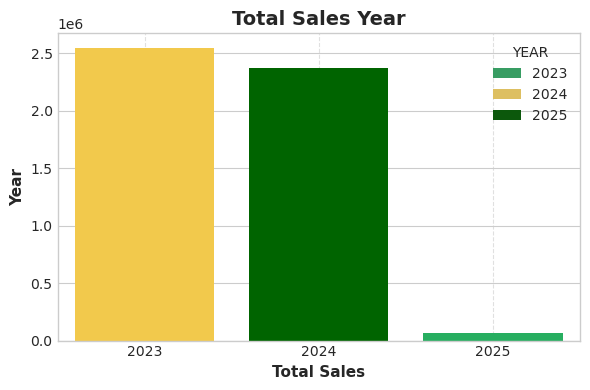

In [27]:
sales_by_year = df1.groupby('YEAR')['TOTAL'].sum().reset_index()

plt.figure(figsize=(6,4))
plt.style.use('seaborn-v0_8-whitegrid')

D_green = '#27AE60'
D_yellow = '#F2C94C'
D_black = '#006400'

ax = sns.barplot(
    x='YEAR',
    y='TOTAL',
    data=sales_by_year,
    hue='YEAR',
    palette=[D_green, D_yellow, D_black]
)

# Title & labels
plt.title('Total Sales Year', fontsize=14, fontweight='bold')
plt.xlabel('Total Sales', fontsize=11, fontweight='bold')
plt.ylabel('Year', fontsize=11, fontweight='bold')

# Grid styling
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Highlight highest sales bar
ax.patches[0].set_facecolor(D_yellow)
ax.patches[1].set_facecolor(D_black)
ax.patches[2].set_facecolor(D_green)


plt.tight_layout()
plt.show()